In [1]:
#!/usr/bin/env python3
"""
==============================================================================
SWOT VALIDATION OF THE CONNECTIVITY STATES  (haor_swot_validation.ipynb)
==============================================================================
Written after the 1 October meeting. Prof. Yamazaki: "From the inundation map
alone it is difficult to judge whether the haors are connected. Sentinel-1 is
for discussing CHANGES in connectivity status; to judge whether they are REALLY
connected, use SWOT. On a day you judge them not merged, the water surface
should look step-wise across the boundary. On the day you say merged, the step
disappears. That is validation. Focus on 2023 onward, where SWOT exists."

The earlier SWOT work compared one median height per haor (Part B). That cannot
show a step AT a boundary, and its headline (adjacent 91% against indirect 34%)
compared two kinds of MERGED pairs with each other, so it never tested merged
against separate for the same pairs. This notebook works from the individual
SWOT pixels instead.

CELL MAP
  S1  inventory: every SWOT pass, coverage per haor, matched radar state
  S2  real maps of SWOT water height for every pass, radar bodies outlined
  S3  boundary transects: height against distance across each shared boundary,
      merged and separate passes side by side (the "step" figure)
  S4  THE STEP TEST: |step| on merged against separate passes, against a
      placebo line inside one haor, with a date-level permutation test
  S5  component test: does each radar body sit at its own level?
  S6  Part B redone with the missing control (adjacent merged vs adjacent separate)
  S7  per-haor SWOT height through 2023 to 2025 with the radar state shaded
  S8  exploratory: water level at the moment a pair separates (sill estimate)
  S9  scorecard

INPUTS  validation/swot_pixels_all/   from haor_swot_extract_pixels_all.py
        validation/labels/            from haor_validation_labels.py
        the per-year CSVs and swot_pair_validation.csv from the main notebook
==============================================================================
"""
import os, sys, re, glob, datetime
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import rasterio
from rasterio.plot import plotting_extent
from rasterio.transform import rowcol
from shapely.geometry import Point
from shapely import affinity
from scipy.stats import mannwhitneyu
print("✓ imports ok")

✓ imports ok


In [2]:
# ============================ PATHS & SETTINGS ============================
CODE_DIR      = "/work/a06/wasif"
BASE          = "/work/a06/wasif/haor_flood_analysis_hydroyear"
ANALYSIS_ROOT = os.path.join(BASE, "analysis")
VAL           = os.path.join(ANALYSIS_ROOT, "validation")
PIX_DIR       = os.path.join(VAL, "swot_pixels_all")
LABELS        = os.path.join(VAL, "labels")
FIGS          = os.path.join(VAL, "figs_swot")
OUTD          = os.path.join(VAL, "swot")
HAORS_SHP     = "/work/a06/wasif/haor_flood_analysis/digitization/haors_manual.shp"
SWOT_PAIRS    = os.path.join(ANALYSIS_ROOT, "swot_pair_validation.csv")
for d in (FIGS, OUTD): os.makedirs(d, exist_ok=True)
sys.path.insert(0, CODE_DIR)
import haor_validation_core as core

UTM = "EPSG:32646"
MATCH_DAYS     = 3       # radar date must be within this many days of the pass
WATER_FRAC_MIN = 0.5     # the strict map filter used for Part C2
QUAL_MAX       = 1
UNCERT_MAX     = 1.0
MIN_PX_HAOR    = 30      # pixels a haor needs on a pass to count as covered
TRANSECT_M     = 2000    # use pixels up to this far from the boundary
EXCLUDE_M      = 300     # ...but not closer than this (mixed pixels, the embankment itself)
MIN_PX_SIDE    = 20      # pixels needed on EACH side for a step estimate
PLACEBO_SHIFT  = 2500    # metres the placebo line is moved into the first haor
N_BOOT, N_PERM = 300, 5000
HAOR_COLORS = {"GMA": "#E07856", "TGR": "#1C7293", "HLR": "#0F766E", "SHN": "#7C3AED", "MTN": "#0A2540"}

os.environ["SHAPE_RESTORE_SHX"] = "YES"
haors = gpd.read_file(HAORS_SHP)
haors = haors[haors["haor_id"] != "DUMMY"].copy()
if (~haors.geometry.is_valid).any():
    haors["geometry"] = haors.geometry.buffer(0)
HAOR_IDS = haors["haor_id"].tolist()
hU = haors.to_crs(UTM).set_index("haor_id")
adj = core.adjacency(haors)
ADJ = adj.loc[adj.adjacent, "pair"].tolist()

YEARS = sorted(int(re.search(r"(\d{4})", os.path.basename(f)).group(1))
               for f in glob.glob(os.path.join(BASE, "flood_stack_cluster_*.tif")))
conn, mats, curves = {}, {}, {}
for y in YEARS:
    d = os.path.join(ANALYSIS_ROOT, str(y))
    conn[y] = pd.read_csv(os.path.join(d, f"connectivity_curve_{y}.csv"))
    mats[y] = pd.read_csv(os.path.join(d, f"haor_connection_matrix_{y}.csv"))
    curves[y] = pd.read_csv(os.path.join(d, f"haor_hydrograph_curves_{y}.csv"))
    curves[y]["cluster_frac"] = curves[y][HAOR_IDS].mean(axis=1)

IX = pd.read_csv(os.path.join(PIX_DIR, "index.csv"))
IX["date"] = pd.to_datetime(IX["date"]).dt.date
# one entry per calendar date; keep 100 m granules when they exist
IX["is100"] = IX["res"].eq("100m")
keep = IX.groupby("date")["is100"].transform("max")
IX = IX[(IX.is100 == keep)]
print(f"SWOT: {len(IX)} granules on {IX.date.nunique()} dates, {IX.date.min()} to {IX.date.max()}")
print("adjacent pairs:", ADJ)

SWOT: 316 granules on 165 dates, 2023-07-29 to 2026-01-11
adjacent pairs: ['SHN-GMA', 'HLR-GMA']


In [3]:
# ============================ HELPERS ============================
def match_radar(date):
    """Nearest scored radar date within MATCH_DAYS. A January to March pass belongs
    to the previous analysis year (day index above 365), as in cell 18."""
    best = None
    for ay in (date.year, date.year - 1):
        if ay not in mats:
            continue
        di = (date - datetime.date(ay, 1, 1)).days
        m = mats[ay][mats[ay][HAOR_IDS[0]] >= 0]
        if not len(m):
            continue
        k = (m["doy"] - di).abs().idxmin()
        gap = abs(m.loc[k, "doy"] - di)
        if gap <= MATCH_DAYS and (best is None or gap < best[2]):
            best = (ay, float(m.loc[k, "doy"]), gap)
    if best is None:
        return None
    ay, doy, gap = best
    row = mats[ay].set_index("doy").loc[doy]
    nz = [row[h] for h in HAOR_IDS if row[h] > 0]
    c = curves[ay]
    return dict(year=ay, doy=doy, gap=gap, row=row,
                all_connected=len(nz) == len(HAOR_IDS) and len(set(nz)) == 1,
                cluster_frac=float(c.loc[(c.doy - doy).abs().idxmin(), "cluster_frac"]))

def pair_state(row, a, b):
    if row[a] <= 0 or row[b] <= 0:
        return "no water"
    return "merged" if row[a] == row[b] else "separate"

_PASS_CACHE = {}
def load_pass(date):
    """All strict-QC pixels of one date, with UTM x/y and haor membership.
    Cached, because several cells read the same pass."""
    if date in _PASS_CACHE:
        return _PASS_CACHE[date]
    _PASS_CACHE[date] = _load_pass(date)
    return _PASS_CACHE[date]

def _load_pass(date):
    frames = []
    for f in IX.loc[IX.date == date, "file"]:
        z = np.load(os.path.join(PIX_DIR, f))
        frames.append(pd.DataFrame({k: z[k] for k in z.files}))
    if not frames:
        return None
    df = pd.concat(frames, ignore_index=True)
    df = df[(df.water_frac >= WATER_FRAC_MIN) & (df.wse_qual <= QUAL_MAX) &
            (df.wse_uncert <= UNCERT_MAX) & np.isfinite(df.wse)].copy()
    if not len(df):
        return df
    g = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.lon, df.lat), crs="EPSG:4326").to_crs(UTM)
    df["x"], df["y"] = g.geometry.x.values, g.geometry.y.values
    j = gpd.sjoin(g[["geometry"]], hU.reset_index()[["haor_id", "geometry"]], predicate="within", how="left")
    j = j[~j.index.duplicated()]
    df["haor_id"] = j["haor_id"].reindex(df.index).values
    # keep only what the cells use, in float32: the cache then holds every pass
    # of a season in a few hundred MB
    keep = [c for c in ["lon", "lat", "x", "y", "wse", "wse_uncert", "wse_qual", "water_frac", "haor_id"] if c in df]
    df = df[keep].reset_index(drop=True)
    for c in keep:
        if c != "haor_id":
            df[c] = df[c].astype("float32")
    return df

def radar_label_at(df, year, doy):
    f = os.path.join(LABELS, f"labels_{year}.tif")
    if not os.path.exists(f) or df is None or not len(df):
        return None
    with rasterio.open(f) as s:
        idx = {core.dayidx(d, year): i + 1 for i, d in enumerate(s.descriptions)}
        if doy not in idx:
            return None
        lab = s.read(idx[doy])
        r, c = rowcol(s.transform, df.lon.values, df.lat.values)
    r, c = np.asarray(r), np.asarray(c)
    ok = (r >= 0) & (r < lab.shape[0]) & (c >= 0) & (c < lab.shape[1])
    out = np.zeros(len(df), int)
    out[ok] = lab[r[ok], c[ok]]
    return out

def shared_line(a, b):
    """Shared boundary of two haors in UTM (boundary of a within 50 m of b)."""
    return hU.geometry[a].boundary.intersection(hU.geometry[b].buffer(50))

def signed_distance(df, line, a, b):
    """Distance to the shared boundary, negative inside haor a, positive inside b."""
    pts = gpd.GeoSeries(gpd.points_from_xy(df.x, df.y), crs=UTM)
    d = pts.distance(line).values
    side = np.where(df.haor_id.values == a, -1.0, np.where(df.haor_id.values == b, 1.0, np.nan))
    return d * side

def step_estimate(sd, wse, rng):
    a = wse[(sd < -EXCLUDE_M) & (sd >= -TRANSECT_M)]
    b = wse[(sd > EXCLUDE_M) & (sd <= TRANSECT_M)]
    if len(a) < MIN_PX_SIDE or len(b) < MIN_PX_SIDE:
        return None
    st = float(np.median(b) - np.median(a))
    boots = [np.median(rng.choice(b, len(b))) - np.median(rng.choice(a, len(a))) for _ in range(N_BOOT)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return dict(step=st, ci_lo=float(lo), ci_hi=float(hi), n_a=len(a), n_b=len(b))
print("✓ helpers defined")

✓ helpers defined


165 SWOT dates | matched to a radar date within 3 days: 164 | usable (>= 2 haors covered): 158
of the usable dates, radar says ALL MERGED on 14


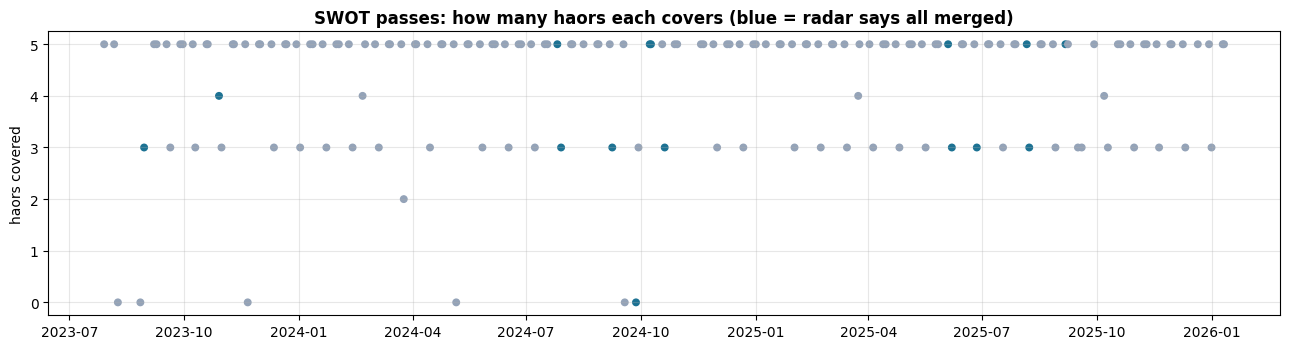

In [4]:
# ============ S1: INVENTORY OF EVERY SWOT PASS ============
rows = []
for date in sorted(IX.date.unique()):
    df = load_pass(date)
    m = match_radar(date)
    r = dict(date=date, n_strict=0 if df is None else len(df))
    for h in HAOR_IDS:
        r[f"px_{h}"] = 0 if df is None or not len(df) else int((df.haor_id == h).sum())
    r["haors_covered"] = sum(r[f"px_{h}"] >= MIN_PX_HAOR for h in HAOR_IDS)
    if m:
        r.update(radar_year=m["year"], radar_doy=m["doy"], gap_days=m["gap"],
                 all_connected=m["all_connected"], cluster_frac=round(m["cluster_frac"], 3))
    rows.append(r)
INV = pd.DataFrame(rows)
INV.to_csv(os.path.join(OUTD, "swot_inventory.csv"), index=False)
usable = INV[(INV.haors_covered >= 2) & INV.radar_year.notna()] if "radar_year" in INV else INV.iloc[0:0]
print(f"{len(INV)} SWOT dates | matched to a radar date within {MATCH_DAYS} days: "
      f"{INV.get('radar_year', pd.Series(dtype=float)).notna().sum()} | usable (>= 2 haors covered): {len(usable)}")
print(f"of the usable dates, radar says ALL MERGED on {int(usable.all_connected.sum())}")
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.scatter(pd.to_datetime(INV.date), INV.haors_covered, c=np.where(INV.get("all_connected", False) == True, "#1C7293", "#94A3B8"), s=22)
ax.set_ylabel("haors covered"); ax.set_title("SWOT passes: how many haors each covers (blue = radar says all merged)", fontweight="bold")
ax.grid(alpha=.3); plt.tight_layout(); plt.savefig(os.path.join(FIGS, "S1_inventory.png"), dpi=150); plt.show()

In [5]:
# ============ S2: REAL MAPS OF SWOT WATER HEIGHT, EVERY PASS ============
# "Show the actual data." Each map is the SWOT pixels themselves, coloured by
# water height, with the haor outlines and the outline of the radar's water
# bodies on the matched date. On a merged date one body surrounds everything
# and the colours should be uniform; on a separate date the bodies split and
# the colours should change across the split.
MAX_MAPS = None            # set a number to limit
done = 0
for _, r in usable.sort_values("date").iterrows():
    if MAX_MAPS and done >= MAX_MAPS: break
    df = load_pass(r.date)
    if df is None or len(df) < 50: continue
    fig, ax = plt.subplots(figsize=(8.5, 6.8))
    lo, hi = np.nanpercentile(df.wse, [2, 98])
    if hi - lo < 0.1: lo, hi = lo - 0.05, hi + 0.05
    sc = ax.scatter(df.lon, df.lat, c=df.wse, s=3, cmap="viridis", vmin=lo, vmax=hi, lw=0)
    plt.colorbar(sc, ax=ax, fraction=.04, label="SWOT water surface elevation (m)")
    lf = os.path.join(LABELS, f"labels_{int(r.radar_year)}.tif")
    if os.path.exists(lf):
        with rasterio.open(lf) as s:
            idx = {core.dayidx(d, int(r.radar_year)): i + 1 for i, d in enumerate(s.descriptions)}
            if r.radar_doy in idx:
                lab = s.read(idx[r.radar_doy]); ext = plotting_extent(s)
                xs = np.linspace(ext[0], ext[1], lab.shape[1]); ys = np.linspace(ext[3], ext[2], lab.shape[0])
                ax.contour(xs, ys, (lab > 0).astype(float), levels=[.5], colors="k", linewidths=.7)
    for _, h in haors.iterrows():
        gpd.GeoSeries([h.geometry.boundary]).plot(ax=ax, color=HAOR_COLORS.get(h.haor_id, "k"), lw=2)
        p = h.geometry.representative_point()
        med = df.loc[df.haor_id == h.haor_id, "wse"].median()
        ax.annotate(f"{h.haor_id}\n{med:.2f} m" if np.isfinite(med) else h.haor_id, (p.x, p.y), ha="center",
                    fontsize=8, fontweight="bold", color=HAOR_COLORS.get(h.haor_id, "k"),
                    bbox=dict(fc="white", alpha=.8, lw=0, boxstyle="round,pad=.15"))
    ax.set_xlim(90.93, 91.34); ax.set_ylim(24.91, 25.22); ax.set_aspect("equal")
    ax.set_title(f"SWOT {r.date}  |  radar {'ALL MERGED' if r.all_connected else 'not all merged'} "
                 f"(+-{int(r.gap_days)} d), flooded {r.cluster_frac:.2f}\nblack line = radar water bodies",
                 fontsize=11, fontweight="bold")
    plt.tight_layout(); plt.savefig(os.path.join(FIGS, f"S2_wse_{r.date}.png"), dpi=130); plt.close(fig)
    done += 1
print(f"wrote {done} SWOT maps to {FIGS} (S2_wse_<date>.png). Look through them in order of date.")

wrote 158 SWOT maps to /work/a06/wasif/haor_flood_analysis_hydroyear/analysis/validation/figs_swot (S2_wse_<date>.png). Look through them in order of date.


171 pair-pass step estimates on 86 passes
         abs_step                                                  abs_placebo                                                 
            count   mean    std    min    25%    50%    75%    max       count   mean    std    min    25%    50%    75%    max
state                                                                                                                          
merged       40.0  0.059  0.165  0.001  0.018  0.032  0.046  1.066        35.0  0.030  0.038  0.001  0.011  0.019  0.028  0.191
no water     29.0  0.882  0.568  0.002  0.617  0.770  0.989  2.004        22.0  0.150  0.197  0.003  0.048  0.089  0.162  0.900
separate    102.0  0.178  0.355  0.000  0.018  0.045  0.157  2.131        76.0  0.086  0.201  0.001  0.007  0.022  0.053  1.160


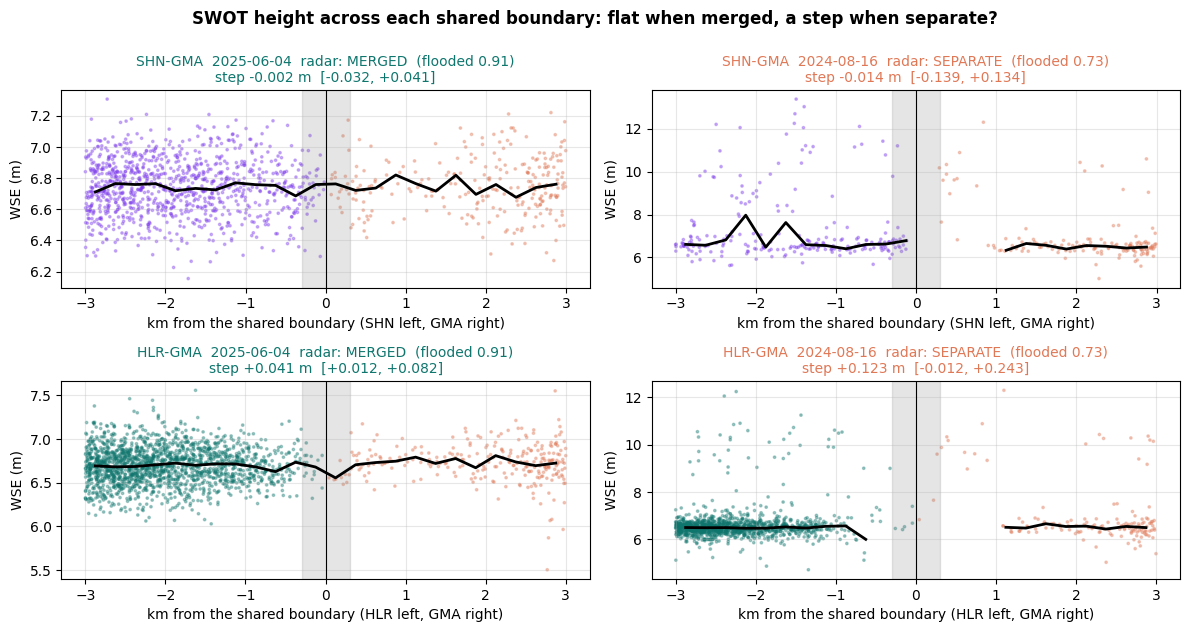


=== THE STEP TEST ===
                      scope  n_merged  n_separate  median_abs_step_merged  median_abs_step_separate  median_abs_placebo  share_separate_with_ci_excl_0  share_merged_with_ci_excl_0  difference   p_perm
                 all passes        40         102                   0.032                     0.045               0.023                          0.363                        0.325       0.013 0.027395
wet passes (flooded >= 0.6)        37          27                   0.032                     0.021               0.019                          0.111                        0.297      -0.011 0.901620

Per pair, median |step| (m):
state    merged  no water  separate
pair                               
HLR-GMA   0.033     0.650     0.053
SHN-GMA   0.027     0.938     0.042

Pre-stated reading:
  SUPPORTS the radar states if, on wet passes, the separate median |step| is larger
  than the merged one with p < 0.05 AND the merged median |step| is no larger than
  about twic

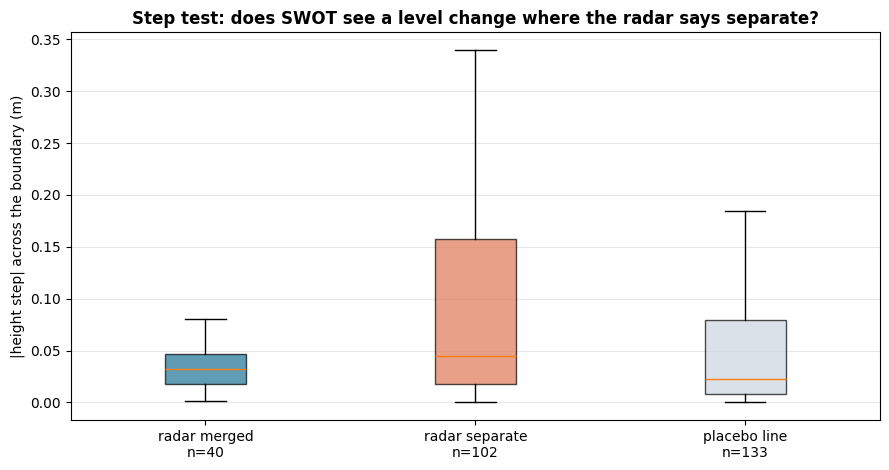

In [6]:
# ============ S3 + S4: THE STEP ACROSS EACH SHARED BOUNDARY ============
# For every pass and every adjacent pair: take SWOT pixels inside the two haors,
# between 300 m and 2 km from their shared boundary, and estimate
#   step = median height on side B - median height on side A
# with a bootstrap interval. Pixels within 300 m are left out: they mix the two
# sides and the embankment itself. The same estimate on a PLACEBO line, moved
# 2.5 km into haor A (so both sides are one water body by construction), gives
# the noise level of the method.
rng = np.random.default_rng(1)
lines = {p: shared_line(*p.split("-")) for p in ADJ}
step_rows = []
for _, r in usable.iterrows():
    df = load_pass(r.date)
    if df is None or not len(df): continue
    m = match_radar(r.date)
    for pair in ADJ:
        a, b = pair.split("-")
        sub = df[df.haor_id.isin([a, b])]
        if (sub.haor_id == a).sum() < MIN_PX_SIDE or (sub.haor_id == b).sum() < MIN_PX_SIDE:
            continue
        sd = signed_distance(sub, lines[pair], a, b)
        est = step_estimate(sd, sub.wse.values, rng)
        if est is None:
            continue
        # placebo: shift the shared line into haor a, use only pixels of haor a
        va = np.array(hU.geometry[a].centroid.coords[0]) - np.array(hU.geometry[b].centroid.coords[0])
        va = va / np.linalg.norm(va) * PLACEBO_SHIFT
        pl = affinity.translate(lines[pair], xoff=va[0], yoff=va[1])
        sa = sub[sub.haor_id == a]
        pts = gpd.GeoSeries(gpd.points_from_xy(sa.x, sa.y), crs=UTM)
        dpl = pts.distance(pl).values
        # which side of the placebo line: compare with distance to the real line
        dreal = pts.distance(lines[pair]).values
        sdp = np.where(dreal > PLACEBO_SHIFT, -dpl, dpl)
        pe = step_estimate(sdp, sa.wse.values, rng)
        step_rows.append(dict(date=r.date, year=m["year"], doy=m["doy"], pair=pair,
                              state=pair_state(m["row"], a, b), all_connected=m["all_connected"],
                              cluster_frac=m["cluster_frac"], **est,
                              placebo_step=pe["step"] if pe else np.nan))
ST = pd.DataFrame(step_rows, columns=["date", "year", "doy", "pair", "state", "all_connected", "cluster_frac",
                                     "step", "ci_lo", "ci_hi", "n_a", "n_b", "placebo_step"])
ST["abs_step"] = ST.step.abs(); ST["abs_placebo"] = ST.placebo_step.abs()
ST["ci_excludes_0"] = (ST.ci_lo > 0) | (ST.ci_hi < 0)
ST.to_csv(os.path.join(OUTD, "boundary_steps.csv"), index=False)
print(f"{len(ST)} pair-pass step estimates on {ST.date.nunique()} passes")
print(ST.groupby("state")[["abs_step", "abs_placebo"]].describe().round(3).to_string())

# ---- S3 figure: profiles for the clearest merged and separate example of each pair ----
pairs_with_both = [p for p in ADJ if {"merged", "separate"} <= set(ST.loc[ST.pair == p, "state"])]
if pairs_with_both:
    fig, ax = plt.subplots(len(pairs_with_both), 2, figsize=(12, 3.2 * len(pairs_with_both)), squeeze=False)
    for i, pair in enumerate(pairs_with_both):
        a, b = pair.split("-")
        g = ST[ST.pair == pair]
        # level matched: separate example closest in flooded fraction to the merged example
        gm = g[g.state == "merged"].sort_values("cluster_frac", ascending=False).iloc[0]
        gs = g[g.state == "separate"].iloc[(g[g.state == "separate"].cluster_frac - gm.cluster_frac).abs().argsort()].iloc[0]
        for j, ex in enumerate([gm, gs]):
            df = load_pass(ex.date); sub = df[df.haor_id.isin([a, b])]
            sd = signed_distance(sub, lines[pair], a, b); k = np.abs(sd) <= 3000
            ax[i][j].scatter(sd[k] / 1000, sub.wse.values[k], s=3, alpha=.35, c=np.where(sd[k] < 0, HAOR_COLORS.get(a, "k"), HAOR_COLORS.get(b, "k")))
            bins = np.arange(-3000, 3001, 250); mid = (bins[:-1] + bins[1:]) / 2
            med = [np.median(sub.wse.values[k][(sd[k] >= lo) & (sd[k] < hi)]) if ((sd[k] >= lo) & (sd[k] < hi)).sum() > 5 else np.nan
                   for lo, hi in zip(bins[:-1], bins[1:])]
            ax[i][j].plot(mid / 1000, med, "k-", lw=2)
            ax[i][j].axvspan(-EXCLUDE_M / 1000, EXCLUDE_M / 1000, color="grey", alpha=.2)
            ax[i][j].axvline(0, color="k", lw=.8)
            ax[i][j].set_title(f"{pair}  {ex.date}  radar: {ex.state.upper()}  (flooded {ex.cluster_frac:.2f})\n"
                               f"step {ex.step:+.3f} m  [{ex.ci_lo:+.3f}, {ex.ci_hi:+.3f}]", fontsize=10,
                               color="#0F766E" if ex.state == "merged" else "#E07856")
            ax[i][j].set_xlabel(f"km from the shared boundary ({a} left, {b} right)"); ax[i][j].set_ylabel("WSE (m)")
            ax[i][j].grid(alpha=.3)
    fig.suptitle("SWOT height across each shared boundary: flat when merged, a step when separate?", fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.985]); plt.savefig(os.path.join(FIGS, "S3_boundary_profiles.png"), dpi=150); plt.show()

# ---- S4: the test ----
def perm_test(g, n=N_PERM, rng=np.random.default_rng(2)):
    """One-sided: is median |step| on separate passes larger than on merged ones?
    The merged/separate labels are shuffled WITHIN each pair, so a pair that is
    always noisy (few pixels, a long boundary) cannot create the result alone."""
    g = g[g.state.isin(["merged", "separate"])]
    v = g.abs_step.values; lab = (g.state == "separate").values
    grp = [np.where(g.pair.values == p)[0] for p in g.pair.unique()]
    obs = np.median(v[lab]) - np.median(v[~lab]); cnt = 0
    perm = lab.copy()
    for _ in range(n):
        for ix in grp:
            perm[ix] = rng.permutation(lab[ix])
        if perm.all() or (~perm).all():
            continue
        cnt += (np.median(v[perm]) - np.median(v[~perm])) >= obs
    return obs, (cnt + 1) / (n + 1)

res = []
for scope, g in [("all passes", ST), ("wet passes (flooded >= 0.6)", ST[ST.cluster_frac >= 0.6])]:
    x = g.loc[g.state == "merged", "abs_step"].values; y = g.loc[g.state == "separate", "abs_step"].values
    if len(x) >= 5 and len(y) >= 5:
        d, pv = perm_test(g)
        res.append(dict(scope=scope, n_merged=len(x), n_separate=len(y),
                        median_abs_step_merged=round(np.median(x), 3), median_abs_step_separate=round(np.median(y), 3),
                        median_abs_placebo=round(np.nanmedian(g.abs_placebo), 3),
                        share_separate_with_ci_excl_0=round(g.loc[g.state == "separate", "ci_excludes_0"].mean(), 3),
                        share_merged_with_ci_excl_0=round(g.loc[g.state == "merged", "ci_excludes_0"].mean(), 3),
                        difference=round(d, 3), p_perm=pv))
S4 = pd.DataFrame(res)
print("\n=== THE STEP TEST ===")
print(S4.to_string(index=False))
print("\nPer pair, median |step| (m):")
print(ST.pivot_table(index="pair", columns="state", values="abs_step", aggfunc="median").round(3).to_string())
S4.to_csv(os.path.join(OUTD, "step_test.csv"), index=False)
print("""
Pre-stated reading:
  SUPPORTS the radar states if, on wet passes, the separate median |step| is larger
  than the merged one with p < 0.05 AND the merged median |step| is no larger than
  about twice the placebo (the noise of the method).
  FAILS if merged and separate steps look the same: then the radar 'separate'
  label does not correspond to different water levels, which is the levee problem
  (both sides wet at 100 m, but not one water surface) or a measurement limit.""")

fig, ax = plt.subplots(figsize=(9, 4.8))
data = [ST.loc[ST.state == "merged", "abs_step"], ST.loc[ST.state == "separate", "abs_step"], ST["abs_placebo"].dropna()]
bp = ax.boxplot(data, tick_labels=[f"radar merged\nn={len(data[0])}", f"radar separate\nn={len(data[1])}", f"placebo line\nn={len(data[2])}"],
                showfliers=False, patch_artist=True)
for p_, c in zip(bp["boxes"], ["#1C7293", "#E07856", "#CBD5E1"]): p_.set_facecolor(c); p_.set_alpha(.7)
ax.set_ylabel("|height step| across the boundary (m)"); ax.grid(alpha=.3, axis="y")
ax.set_title("Step test: does SWOT see a level change where the radar says separate?", fontweight="bold")
plt.tight_layout(); plt.savefig(os.path.join(FIGS, "S4_step_test.png"), dpi=160); plt.show()

In [7]:
# ============ S5: DOES EACH RADAR BODY SIT AT ITS OWN LEVEL? ============
# This is the 'component-aware' comparison proposed after Oxford (C1 v4), done
# with pixels. Each SWOT pixel inside a haor gets the label of the radar body it
# falls in on the matched date. Within one body, haor medians should agree.
# Between two bodies, on separate dates, they may differ.
crow = []
for _, r in usable.iterrows():
    df = load_pass(r.date)
    if df is None or not len(df): continue
    lab = radar_label_at(df, int(r.radar_year), float(r.radar_doy))
    if lab is None: continue
    df = df.assign(body=lab)
    d = df[(df.body > 0) & df.haor_id.notna()]
    med = d.groupby(["body", "haor_id"]).wse.agg(["median", "size"]).reset_index()
    med = med[med["size"] >= MIN_PX_HAOR]
    for body, g in med.groupby("body"):
        if len(g) >= 2:
            crow.append(dict(date=r.date, kind="within one body", diff=float(g["median"].max() - g["median"].min())))
    bm = d.groupby("body").wse.agg(["median", "size"]); bm = bm[bm["size"] >= 3 * MIN_PX_HAOR]
    if len(bm) >= 2:
        crow.append(dict(date=r.date, kind="between bodies", diff=float(bm["median"].max() - bm["median"].min())))
CB = pd.DataFrame(crow)
if len(CB):
    print(CB.groupby("kind")["diff"].describe().round(3).to_string())
    x, y = CB.loc[CB.kind == "within one body", "diff"], CB.loc[CB.kind == "between bodies", "diff"]
    if len(x) > 3 and len(y) > 3:
        print(f"\nMann-Whitney (between > within): p = {mannwhitneyu(y, x, alternative='greater').pvalue:.2e}")
    CB.to_csv(os.path.join(OUTD, "component_levels.csv"), index=False)
else:
    print("needs the label rasters (haor_validation_labels.py)")

                 count   mean    std    min    25%    50%    75%    max
kind                                                                   
between bodies    85.0  0.349  0.480  0.000  0.176  0.252  0.334  3.532
within one body  125.0  0.130  0.177  0.001  0.041  0.079  0.176  1.435

Mann-Whitney (between > within): p = 4.18e-15


In [8]:
# ============ S6: PART B REDONE WITH THE MISSING CONTROL ============
# The Oxford headline compared ADJACENT merged pairs (91% within 0.15 m) with
# INDIRECT merged pairs (34%). Both groups are 'merged', so the difference says
# that nearby basins have closer levels than distant ones; it says nothing about
# whether merging changes the level. The control is: adjacent MERGED against
# adjacent SEPARATE, and indirect merged against indirect separate. Intervals
# come from resampling whole DATES, because the pairs on one date share one pass.
PARTB = {}
if os.path.exists(SWOT_PAIRS):
    P = pd.read_csv(SWOT_PAIRS)
    adjset = set(ADJ) | {"-".join(p.split("-")[::-1]) for p in ADJ}
    P["adjacency"] = np.where(P.pair.isin(adjset), "adjacent", "indirect")
    tab = P.groupby(["adjacency", "state"]).dwse.agg(n="size", median="median",
            within_015=lambda s: (s <= 0.15).mean()).round(3)
    print(tab.to_string())
    rng = np.random.default_rng(3)
    for adjc in ["adjacent", "indirect"]:
        g = P[P.adjacency == adjc]
        # one block of pairs per date; a bootstrap draw picks whole dates
        blocks = [(gg.loc[gg.state == "merged", "dwse"].values, gg.loc[gg.state == "separate", "dwse"].values)
                  for _, gg in g.groupby(["analysis_year", "doy"])]
        diffs = []
        for _ in range(2000):
            pick = rng.integers(0, len(blocks), len(blocks))
            m_ = np.concatenate([blocks[i][0] for i in pick]); s_ = np.concatenate([blocks[i][1] for i in pick])
            if len(m_) and len(s_):
                diffs.append(np.median(s_) - np.median(m_))
        if diffs:
            lo, hi = np.percentile(diffs, [2.5, 97.5])
            PARTB[adjc] = (float(np.median(diffs)), float(lo), float(hi),
                           float(g.loc[g.state == "merged", "dwse"].median()), float(g.loc[g.state == "separate", "dwse"].median()))
            print(f"{adjc:9}: separate minus merged median |dWSE| = {np.median(diffs):+.3f} m, "
                  f"95% date-bootstrap interval [{lo:+.3f}, {hi:+.3f}]"
                  f"  -> {'merged pairs ARE closer' if lo > 0 else 'NOT distinguishable'}")
    print("\nOnly the 'adjacent' line tests the radar labels fairly. Quote it instead of 91 vs 34.")
    print("'Merged pairs are closer' is necessary but not enough: basins that are never connected are also")
    print("closer at high water, when merged dates happen. The scorecard therefore also asks that merged")
    print("pairs sit at no more than half the separate difference. The S4 step test with its placebo is the")
    print("stronger test.")
else:
    print(f"missing {SWOT_PAIRS}; run cell 18 of haor_flood_hydroyear.ipynb")

                      n  median  within_015
adjacency state                            
adjacent  merged     55   0.050       0.945
          separate  133   0.098       0.571
indirect  merged    155   0.122       0.677
          separate  525   0.157       0.480
adjacent : separate minus merged median |dWSE| = +0.047 m, 95% date-bootstrap interval [+0.010, +0.131]  -> merged pairs ARE closer
indirect : separate minus merged median |dWSE| = +0.034 m, 95% date-bootstrap interval [+0.016, +0.059]  -> merged pairs ARE closer

Only the 'adjacent' line tests the radar labels fairly. Quote it instead of 91 vs 34.
'Merged pairs are closer' is necessary but not enough: basins that are never connected are also
closer at high water, when merged dates happen. The scorecard therefore also asks that merged
pairs sit at no more than half the separate difference. The S4 step test with its placebo is the
stronger test.


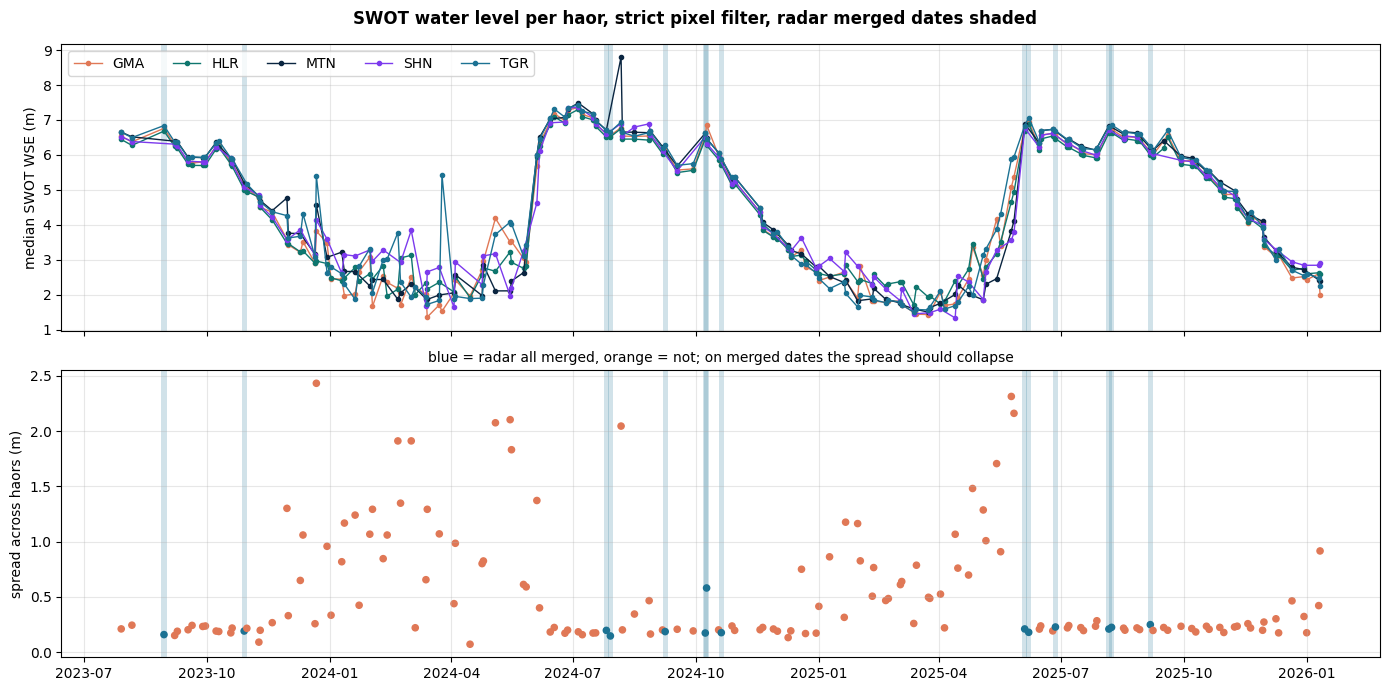

        count   mean    std    min    25%    50%    75%    max
merged                                                        
False   143.0  0.564  0.540  0.072  0.202  0.258  0.810  2.433
True     14.0  0.222  0.107  0.147  0.177  0.194  0.221  0.581


In [9]:
# ============ S7: PER-HAOR SWOT HEIGHT THROUGH THE RECORD ============
ts = []
for _, r in usable.iterrows():
    df = load_pass(r.date)
    if df is None or not len(df): continue
    for h, g in df[df.haor_id.notna()].groupby("haor_id"):
        if len(g) >= MIN_PX_HAOR:
            ts.append(dict(date=r.date, haor=h, wse=g.wse.median(), all_connected=r.all_connected))
TS = pd.DataFrame(ts)
if len(TS):
    TS["date"] = pd.to_datetime(TS["date"])
    fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    for d, g in TS.groupby("date"):
        if g.all_connected.iloc[0]:
            for a_ in ax: a_.axvspan(d - pd.Timedelta(days=2), d + pd.Timedelta(days=2), color="#1C7293", alpha=.2, lw=0)
    for h, g in TS.groupby("haor"):
        ax[0].plot(g.date, g.wse, "o-", ms=3, lw=1, color=HAOR_COLORS.get(h, "k"), label=h)
    ax[0].set_ylabel("median SWOT WSE (m)"); ax[0].legend(ncol=5); ax[0].grid(alpha=.3)
    sp = TS.groupby("date").agg(spread=("wse", lambda s: s.max() - s.min()), n=("wse", "size"),
                                merged=("all_connected", "first")).reset_index()
    sp = sp[sp.n >= 3]
    ax[1].scatter(sp.date, sp.spread, c=np.where(sp.merged, "#1C7293", "#E07856"), s=20)
    ax[1].set_ylabel("spread across haors (m)"); ax[1].grid(alpha=.3)
    ax[1].set_title("blue = radar all merged, orange = not; on merged dates the spread should collapse", fontsize=10)
    fig.suptitle("SWOT water level per haor, strict pixel filter, radar merged dates shaded", fontweight="bold")
    plt.tight_layout(); plt.savefig(os.path.join(FIGS, "S7_timeseries.png"), dpi=150); plt.show()
    print(sp.groupby("merged").spread.describe().round(3).to_string())

In [10]:
# ============ S8: EXPLORATORY, THE LEVEL AT WHICH A PAIR SEPARATES ============
# When a pair goes from merged to separate between two consecutive SWOT passes,
# the falling surface stood on the sill between them. The mean level of the pair
# at those two passes brackets the sill height. Exploratory: few transitions are
# expected, and every one should be checked on its S2 map before it is believed.
if len(ST):
    trans = []
    for pair, g in ST.sort_values("date").groupby("pair"):
        g = g.reset_index(drop=True)
        for i in range(1, len(g)):
            s0, s1 = g.state[i - 1], g.state[i]
            if {s0, s1} == {"merged", "separate"} and (pd.Timestamp(g.date[i]) - pd.Timestamp(g.date[i - 1])).days <= 30:
                trans.append(dict(pair=pair, from_date=g.date[i - 1], to_date=g.date[i],
                                  direction="separating" if s0 == "merged" else "joining",
                                  step_before=round(g.step[i - 1], 3), step_after=round(g.step[i], 3)))
    TR = pd.DataFrame(trans)
    print(TR.to_string(index=False) if len(TR) else "no merged/separate transitions between passes <= 30 days apart")
    if len(TR): TR.to_csv(os.path.join(OUTD, "transitions.csv"), index=False)

   pair  from_date    to_date  direction  step_before  step_after
HLR-GMA 2023-07-29 2023-08-06 separating        0.017       0.042
HLR-GMA 2023-09-30 2023-10-08 separating        0.043       0.023
HLR-GMA 2023-10-20 2023-10-29    joining        0.000      -0.058
HLR-GMA 2023-10-29 2023-11-09 separating       -0.058      -0.325
HLR-GMA 2024-06-25 2024-07-05    joining        0.014       0.018
HLR-GMA 2024-07-05 2024-07-18 separating        0.018       0.037
HLR-GMA 2024-07-18 2024-07-26    joining        0.037       0.024
HLR-GMA 2024-08-07 2024-08-16 separating        0.026       0.123
HLR-GMA 2024-09-06 2024-09-17    joining        0.053       0.022
HLR-GMA 2024-10-18 2024-10-28 separating        0.056       0.017
HLR-GMA 2025-05-14 2025-05-25    joining        1.180       1.066
HLR-GMA 2025-06-04 2025-06-15 separating        0.041       0.100
HLR-GMA 2025-07-07 2025-07-16    joining        0.014       0.033
HLR-GMA 2025-07-16 2025-07-27 separating        0.033       0.031
HLR-GMA 20

In [11]:
# ============ S9: SCORECARD ============
card = []
if len(S4):
    w = S4[S4.scope.str.startswith("wet")]
    w = w.iloc[0] if len(w) else S4.iloc[0]
    ok = (w.p_perm < 0.05) and (w.median_abs_step_merged <= 2 * max(w.median_abs_placebo, 0.01))
    card.append(("step test, wet passes", "separate |step| > merged, p < 0.05; merged <= 2 x placebo",
                 f"{'PASS' if ok else 'FAIL'} (merged {w.median_abs_step_merged} m, separate {w.median_abs_step_separate} m, "
                 f"placebo {w.median_abs_placebo} m, p = {w.p_perm:.4f})"))
else:
    card.append(("step test", "needs passes covering both sides of a boundary", "PENDING"))
if len(CB):
    x, y = CB.loc[CB.kind == "within one body", "diff"], CB.loc[CB.kind == "between bodies", "diff"]
    if len(x) > 3 and len(y) > 3:
        p5 = mannwhitneyu(y, x, alternative="greater").pvalue
        ok5 = p5 < .05 and x.median() <= 0.5 * y.median()
        card.append(("radar bodies sit at their own levels", "between > within (p < 0.05) AND within-body median <= half the between-body median",
                     f"{'PASS' if ok5 else 'FAIL'} (median within {x.median():.3f} m, between {y.median():.3f} m, p = {p5:.2g})"))
    else:
        card.append(("radar bodies sit at their own levels", "between-body differences > within-body", "too few dates"))
if "adjacent" in PARTB:
    d_, lo_, hi_, mm_, ms_ = PARTB["adjacent"]
    ok6 = lo_ > 0 and mm_ <= 0.5 * ms_
    card.append(("Part B with the proper control", "adjacent: separate minus merged > 0 (date-bootstrap lower bound > 0) AND merged median <= half the separate median",
                 f"{'PASS' if ok6 else 'FAIL'} ({d_:+.3f} m, [{lo_:+.3f}, {hi_:+.3f}]; medians merged {mm_:.3f}, separate {ms_:.3f})"))
else:
    card.append(("Part B with the proper control", "adjacent merged closer than adjacent separate", "PENDING (S6)"))
SC = pd.DataFrame(card, columns=["check", "criterion", "result"])
print(SC.to_string(index=False)); SC.to_csv(os.path.join(VAL, "scorecard_swot.csv"), index=False)

                               check                                                                                                          criterion                                                                  result
               step test, wet passes                                                          separate |step| > merged, p < 0.05; merged <= 2 x placebo    FAIL (merged 0.032 m, separate 0.021 m, placebo 0.019 m, p = 0.9016)
radar bodies sit at their own levels                                 between > within (p < 0.05) AND within-body median <= half the between-body median              PASS (median within 0.079 m, between 0.252 m, p = 4.2e-15)
      Part B with the proper control adjacent: separate minus merged > 0 (date-bootstrap lower bound > 0) AND merged median <= half the separate median FAIL (+0.047 m, [+0.010, +0.131]; medians merged 0.050, separate 0.098)
